# Parte 2 · Grafos ICEWS e análise visual de dados

### Pergunta de pesquisa

**O que as ações e suas intensidades revelam sobre as relações entre os países nos casos analisados no ICEWS?**

O [ICEWS Coded Event Data](https://doi.org/10.7910/DVN/28075), do Harvard Dataverse, reúne eventos políticos codificados a partir de notícias. Usamos o período de 1995 a 2022. A rede tem **250 nós e 29.381 arestas dirigidas e ponderadas**. Para cada par de países distintos, o sentido vai do país do ator que realiza a ação ao país do ator que a recebe.

O peso é a média de `Intensity` dos eventos de cada par. As **2.940 arestas negativas** representam pares com saldo médio desfavorável na escala do ICEWS. Além do peso, usamos a contagem de eventos, o número de anos com registros e a marcação de pares com apenas um evento. Nos dados brutos, também exploramos data, família CAMEO, setor do ator, veículo e país do evento.

In [1]:
import csv
import json
import math
import re
import sys
import textwrap
from collections import Counter, defaultdict
from io import BytesIO
from pathlib import Path
from statistics import correlation, mean, median

import matplotlib
from IPython.display import Image, display

matplotlib.use("Agg")
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from matplotlib.ticker import FuncFormatter

pasta_atual = Path.cwd()
inicio = pasta_atual.resolve()
RAIZ = None

for pasta in (inicio, *inicio.parents):
    algoritmos_existem = (pasta / "src/graphs/algorithms.py").is_file()
    dataset_existe = (pasta / "data/dataset_parte2/arestas_paises.csv").is_file()

    if algoritmos_existem and dataset_existe:
        RAIZ = pasta
        break

if RAIZ is None:
    raise FileNotFoundError("Abra o notebook a partir do repositório projeto-grafos.")

if str(RAIZ) not in sys.path:
    sys.path.insert(0, str(RAIZ))

from src.benchmark_parte2 import (
    DATASET,
    FONTES,
    PARES,
    REPETICOES,
    SAIDA as CAMINHO_RELATORIO,
    SEED,
    executar_pipeline_parte2,
    reconstruir_caminho,
)
from src.graphs.algorithms import bfs, dfs
from src.graphs.graph import montar_grafo_paises
from src.graphs.io import carregar_arestas

PROCESSADO = DATASET / "processado"
SAIDA = CAMINHO_RELATORIO.parent

## 1. Grafo e custo dos caminhos

Cada nó representa um país. A aresta de A para B guarda a intensidade média dos eventos de A para B. O Bellman-Ford usa esse peso original, que vai de −10 a +10.

**Densidade do grafo completo.** Em um grafo dirigido sem laços, existem $|V| × (|V| - 1)$ arestas possíveis. Com 250 nós, são 62.250 arestas possíveis. Como o grafo tem 29.381 arestas, a densidade é $29.381 / 62.250 ≈ 47{,}20\%$.

A BFS procura o caminho com menos saltos. Para o Dijkstra, usamos `10 - peso` como custo: 0 é o menor atrito possível e 20 é o maior. Somamos esse mesmo custo nas duas rotas para comparar a diferença.

Uma aresta com apenas um evento é um par fraco. Na análise de robustez, tiramos essas arestas e mantemos todos os países.

No recorte acíclico, o caminho de menor custo soma os pesos originais e favorece um saldo de intensidade mais negativo. Um ciclo negativo é um circuito dirigido cujo saldo de intensidade é menor que zero. Se um ciclo assim for alcançável e puder levar ao destino, repeti-lo torna o custo arbitrariamente baixo.

## 2. Como medimos o tempo

Rodamos cada tarefa cinco vezes e guardamos a média e o desvio-padrão. Na BFS e na DFS, cada repetição passa pelas três fontes. O Dijkstra roda uma vez por origem dos cinco pares. Cada cenário do Bellman-Ford usa uma origem. A leitura do CSV e a montagem dos grafos ficam fora do cronômetro.

No teste de escalabilidade, usamos 10%, 50% e 100% dos países. A semente 42 permite repetir o sorteio. Em cada subgrafo, todos os algoritmos saem do país com mais arestas de saída. Em caso de empate, vale a ordem alfabética.

## 3. Buscas, ciclos e robustez

O JSON guarda a ordem completa da BFS, a quantidade de países em cada camada e a ordem de descoberta da DFS. A DFS também conta os tipos de aresta e guarda um exemplo de ciclo quando encontra uma aresta de retorno. No grafo completo, guardamos o ciclo negativo que o Bellman-Ford encontra, o custo desse ciclo e os eventos de cada aresta.

No recorte, as arestas seguem a ordem de atividade dos países. Um caminho só pode avançar nessa ordem, o que impede a formação de ciclos. Conferimos o resultado com Bellman-Ford e com a contagem de arestas de retorno da DFS.

Por fim, repetimos Dijkstra e Bellman-Ford sem os pares fracos e vemos quais rotas mudam e se ainda há ciclo negativo.

In [2]:
def completar_buscas(relatorio, pasta_dataset):
    buscas = relatorio["casos_obrigatorios"]["bfs_dfs_3_fontes"]
    campos = {"bfs_ordem", "bfs_camadas", "dfs_ordem_descoberta", "dfs_exemplo_ciclo"}
    fontes_pendentes = []

    for fonte, caso in buscas.items():
        if not campos.issubset(caso):
            fontes_pendentes.append(fonte)

    if not fontes_pendentes:
        return False

    dados_arestas = carregar_arestas(pasta_dataset)
    grafo, informacoes_arestas = montar_grafo_paises(dados_arestas)

    for fonte in fontes_pendentes:
        caso = buscas[fonte]
        distancias, predecessores = bfs(grafo, fonte)
        ordem_bfs = [fonte]
        camadas = {}

        for pais in ordem_bfs:
            camada = str(distancias[pais])
            camadas[camada] = camadas.get(camada, 0) + 1

            for destino, peso in grafo[pais]:
                if predecessores[destino] == pais:
                    ordem_bfs.append(destino)

        descoberta, encerramento, predecessores_dfs, arestas_dfs, tem_ciclo = dfs(grafo, fonte)
        ordem_dfs = []
        for pais, tempo in descoberta.items():
            if tempo is not None:
                ordem_dfs.append(pais)
        ordem_dfs.sort(key=descoberta.get)

        ciclo = []
        if arestas_dfs["retorno"]:
            origem_retorno, destino_retorno = arestas_dfs["retorno"][0]
            ciclo = reconstruir_caminho(predecessores_dfs, destino_retorno, origem_retorno)
            ciclo.append(destino_retorno)

        caso["bfs_ordem"] = ordem_bfs
        caso["bfs_camadas"] = camadas
        caso["dfs_ordem_descoberta"] = ordem_dfs
        caso["dfs_exemplo_ciclo"] = ciclo

    return True


benchmark_atualizado = False

if CAMINHO_RELATORIO.is_file():
    with CAMINHO_RELATORIO.open(encoding="utf-8") as arquivo:
        relatorio = json.load(arquivo)
else:
    relatorio = executar_pipeline_parte2(DATASET, seed=SEED, repeticoes=REPETICOES)
    benchmark_atualizado = True

if completar_buscas(relatorio, DATASET):
    benchmark_atualizado = True

meta = relatorio["metadata"]

print(f"{meta['n_nos_completo']} países | {meta['n_arestas_completo']} arestas | "
      f"{meta['n_negativas_completo']} arestas negativas | {meta['n_pares_fracos']} pares fracos")

n_nos = meta["n_nos_completo"]
n_arestas = meta["n_arestas_completo"]
arestas_possiveis = n_nos * (n_nos - 1)
densidade = n_arestas / arestas_possiveis
densidade_percentual = f"{densidade:.2%}".replace(".", ",")
print(f"Densidade do grafo completo: {densidade_percentual}")

for medida in relatorio["tempo_medio"]:
    print(f"{medida['algoritmo']} · {medida['tarefa']} · "
          f"{medida['media_ms']:.3f} ± {medida['desvio_ms']:.3f} ms")


buscas = relatorio["casos_obrigatorios"]["bfs_dfs_3_fontes"]

for fonte, caso in buscas.items():
    print(f"{fonte} · quantidade por camada da BFS: {caso['bfs_camadas']}")
    primeiros_dfs = ", ".join(caso["dfs_ordem_descoberta"][:5])
    
    print(f"Primeiros países da DFS: {primeiros_dfs}")
    
    if caso["dfs_tem_ciclo"]:
        ciclo_dfs = " → ".join(caso["dfs_exemplo_ciclo"])
        print(f"Exemplo de ciclo pela DFS: {ciclo_dfs}")

recorte = relatorio["casos_obrigatorios"]["bellman_ford_sem_ciclo"]

for fonte, caso in recorte["execucoes"].items():
    print(f"Recorte · {fonte} · {caso['alcancados']} alcançados · "
          f"{caso['dfs_arestas_retorno']} arestas de retorno")

robustez = relatorio["robustez_sem_pares_fracos"]
rotas_alteradas = 0

for rota in robustez["dijkstra_5_pares"]:
    
    if rota["mudou_em_relacao_ao_completo"]:
        rotas_alteradas += 1

print(
    f"Sem pares fracos · {robustez['n_arestas']} arestas · "
    f"{rotas_alteradas} rotas de Dijkstra alteradas"
)

250 países | 29381 arestas | 2940 arestas negativas | 4284 pares fracos
Densidade do grafo completo: 47,20%
BFS · 3_fontes · 13.035 ± 4.224 ms
DFS · 3_fontes · 31.931 ± 8.136 ms
DIJKSTRA · 5_pares · 54.728 ± 2.785 ms
BELLMAN_FORD · completo_com_ciclo · 1777.510 ± 404.604 ms
BELLMAN_FORD · recorte_sem_ciclo · 545.838 ± 70.792 ms
United States · quantidade por camada da BFS: {'0': 1, '1': 239, '2': 10}
Primeiros países da DFS: United States, Afghanistan, Albania, Algeria, Andorra
Exemplo de ciclo pela DFS: Afghanistan → Albania → Afghanistan
Brazil · quantidade por camada da BFS: {'0': 1, '1': 194, '2': 55}
Primeiros países da DFS: Brazil, Afghanistan, Albania, Algeria, Andorra
Exemplo de ciclo pela DFS: Afghanistan → Albania → Afghanistan
Israel · quantidade por camada da BFS: {'0': 1, '1': 184, '2': 64, '3': 1}
Primeiros países da DFS: Israel, Afghanistan, Albania, Algeria, Andorra
Exemplo de ciclo pela DFS: Afghanistan → Albania → Afghanistan
Recorte · United States · 250 alcançados ·

## 4. Gráficos do benchmark

In [3]:
AZUL = "#23689b"
VERMELHO = "#b73c36"
VERDE = "#23857e"
CINZA = "#59636e"
NEUTRO = "#414a54"

PAISES = {
    "Lebanon": "Líbano",
    "Saudi Arabia": "Arábia Saudita",
    "Yemen": "Iêmen",
    "Russian Federation": "Rússia",
    "Ukraine": "Ucrânia",
    "Brazil": "Brasil",
    "Bhutan": "Butão",
    "United States": "Estados Unidos",
    "Iraq": "Iraque",
    "Occupied Palestinian Territory": "Território Palestino Ocupado",
    "Guyana": "Guiana",
}
LOCAIS = {
    "domestico": "Doméstico",
    "domestico_no_exterior": "Doméstico no exterior",
    "sem_pais_ator": "Sem país de um ator",
    "bilateral_no_destino": "Bilateral no destino",
    "bilateral_terceiro_pais": "Bilateral em terceiro país",
    "bilateral_na_origem": "Bilateral na origem",
}
SETORES = {
    "Executive Office": "Gabinete executivo",
    "Center Right": "Centro-direita",
    "Cabinet": "Gabinete ministerial",
    "International Government Organization": "Organização intergovernamental",
    "Foreign Ministry": "Ministério das Relações Exteriores",
    "Dissident": "Dissidência",
    "Police": "Polícia",
    "Military": "Forças armadas",
    "General Population / Civilian / Social": "População geral / Civil / Social",
    "Social": "Social",
    "Government": "Governo",
    "Executive": "Executivo",
    "Elite": "Elite",
    "Head of Government": "Chefia de governo",
    "Media": "Imprensa",
    "Political Opposition": "Oposição política",
    "Parties": "Partidos",
    "(National) Major Party": "Grande partido nacional",
    "Ideological": "Ideológico",
    "Legislative / Parliamentary": "Legislativo / Parlamentar",
}


figuras = {}


def mostrar(fig, nome):
    figuras[nome] = fig
    
    with BytesIO() as previa:
        fig.savefig(
            previa,
            format="png",
            dpi=90,
            bbox_inches="tight",
            facecolor="white",
        )
        
        imagem = Image(data=previa.getvalue(), width=900)
        display(imagem)
    
    plt.close(fig)


def ler_csv(caminho):
    with caminho.open(encoding="utf-8", newline="") as arquivo:
        leitor = csv.DictReader(arquivo)
        linhas = list(leitor)

    return linhas


def rotulo_numero(valor, decimais=0):
    
    if round(valor, decimais) == 0:
        valor = 0
    
    numero = f"{valor:,.{decimais}f}"
    separadores = str.maketrans(",.", ".,")
    
    return numero.translate(separadores)


def nome_par(origem, destino, separador=" "):
    nome_origem = PAISES.get(origem, origem)
    nome_destino = PAISES.get(destino, destino)
    
    return f"{nome_origem} →{separador}{nome_destino}"


def formatar_eixo_decimal(ax, decimais=1):
    ax.yaxis.set_major_formatter(
        FuncFormatter(lambda valor, _pos: rotulo_numero(valor, decimais))
    )


def grade(ax, eixo="y"):
    ax.set_axisbelow(True)
    ax.grid(axis=eixo, color="#d5dce1", linewidth=0.7, alpha=0.8)


def media_da_categoria(categoria):
    rotulo, media = categoria
    return media


def barras_intensidade(ax, dados, titulo, eixo, largura=36, amplitude=None):
    ordenado = sorted(dados, key=media_da_categoria)
    rotulos = []
    valores = []
    cores = []

    for rotulo, valor in ordenado:
        rotulo_quebrado = textwrap.fill(rotulo, largura, break_long_words=False)
        rotulos.append(rotulo_quebrado)
        valores.append(valor)

        if valor > 0:
            cores.append(AZUL)
        elif valor < 0:
            cores.append(VERMELHO)
        else:
            cores.append(NEUTRO)

    if amplitude is None:
        menor_valor = abs(min(valores))
        maior_valor = abs(max(valores))
        amplitude = math.ceil(max(menor_valor, maior_valor))
        amplitude = max(1, amplitude)

    posicoes = range(len(valores))
    ax.barh(posicoes, valores, color=cores, height=0.67)
    ax.set_yticks(posicoes, rotulos)
    ax.tick_params(axis="y", length=0, pad=8)
    ax.axvline(0, color=NEUTRO, linewidth=1, zorder=3)

    for posicao, valor in zip(posicoes, valores):
        texto = rotulo_numero(valor, 2).replace("-", "−")
        alinhamento = "left"
        deslocamento = 6

        if valor < 0:
            alinhamento = "right"
            deslocamento = -6
        elif valor > 0:
            texto = "+" + texto

        ax.annotate(
            texto,
            (valor, posicao),
            xytext=(deslocamento, 0),
            textcoords="offset points",
            ha=alinhamento,
            va="center",
            fontsize=10,
            color=NEUTRO,
        )

    marcas = [-amplitude, -amplitude / 2, 0, amplitude / 2, amplitude]
    rotulos_eixo = []
    for marca in marcas:
        casas_decimais = 0
        if marca != int(marca):
            casas_decimais = 1
        rotulo = rotulo_numero(marca, casas_decimais).replace("-", "−")
        rotulos_eixo.append(rotulo)

    margem = amplitude * 0.18
    ax.set_xticks(marcas, rotulos_eixo)
    ax.set(
        title=titulo,
        xlabel="Intensidade média",
        ylabel=eixo,
        xlim=(-amplitude - margem, amplitude + margem),
    )
    ax.spines["left"].set_visible(False)
    grade(ax, "x")


def legenda_intensidade():
    return [
        Patch(color=AZUL, label="Média positiva"),
        Patch(color=VERMELHO, label="Média negativa"),
        Line2D([], [], color=NEUTRO, linewidth=1, label="Intensidade = 0"),
    ]


def series_intensidade(dados, chave, nomes):
    series = []
    for item in dados:
        categoria = item[chave]
        rotulo = nomes.get(categoria, categoria)
        media = float(item["media_intensidade"])
        series.append((rotulo, media))

    return series


plt.rcParams.update({
    "font.size": 11,
    "axes.titlesize": 13,
    "figure.titlesize": 17,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

### Tempo médio por tarefa

As barras mostram a média e as linhas no topo mostram o desvio-padrão. O painel de Bellman-Ford usa segundos. O painel de BFS, DFS e Dijkstra usa milissegundos.

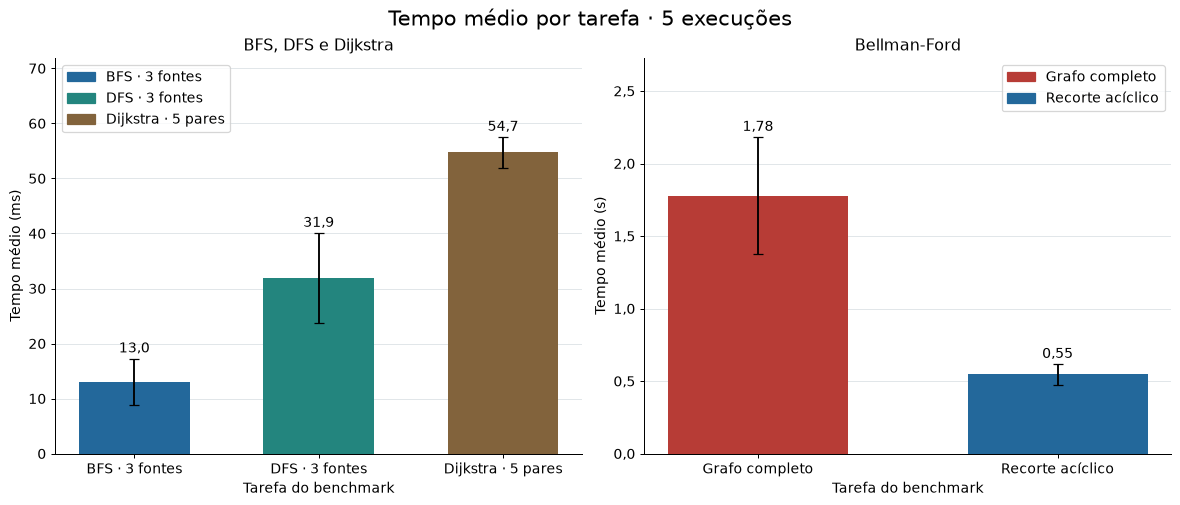

In [4]:
def tempo_medio(relatorio):
    fig, eixos = plt.subplots(1, 2, figsize=(13, 5.5), layout="constrained")
    fig.suptitle(f"Tempo médio por tarefa · {relatorio['metadata']['repeticoes']} execuções")
    dados = relatorio["tempo_medio"]
    
    paineis = [
        {
            "eixo": eixos[0],
            "tarefas": dados[:3],
            "rotulos": ("BFS · 3 fontes", "DFS · 3 fontes", "Dijkstra · 5 pares"),
            "cores": (AZUL, VERDE, "#82633c"),
            "fator": 1,
            "unidade": "ms",
            "decimais_rotulo": 1,
            "decimais_eixo": 0,
            "titulo": "BFS, DFS e Dijkstra",
        },
        {
            "eixo": eixos[1],
            "tarefas": dados[3:],
            "rotulos": ("Grafo completo", "Recorte acíclico"),
            "cores": (VERMELHO, AZUL),
            "fator": 1000,
            "unidade": "s",
            "decimais_rotulo": 2,
            "decimais_eixo": 1,
            "titulo": "Bellman-Ford",
        },
    ]

    for painel in paineis:
        ax = painel["eixo"]
        itens = painel["tarefas"]
        fator = painel["fator"]
        unidade = painel["unidade"]
        nomes = painel["rotulos"]
        paleta = painel["cores"]
        valores = []
        desvios = []
    
        for item in itens:
            valores.append(item["media_ms"] / fator)
            desvios.append(item["desvio_ms"] / fator)

        grade(ax)
        barras = ax.bar(nomes, valores, yerr=desvios, color=paleta, capsize=4, width=0.6)
        maior_altura = 0
    
        for barra, valor, desvio in zip(barras, valores, desvios):
            centro = barra.get_x() + barra.get_width() / 2
            altura = valor + desvio
            maior_altura = max(maior_altura, altura)
    
            ax.annotate(
                rotulo_numero(valor, painel["decimais_rotulo"]),
                (centro, altura),
                xytext=(0, 5),
                textcoords="offset points",
                ha="center",
            )

        ax.set(
            ylim=(0, maior_altura * 1.25),
            xlabel="Tarefa do benchmark",
            ylabel=f"Tempo médio ({unidade})",
            title=painel["titulo"],
        )
    
        formatar_eixo_decimal(ax, painel["decimais_eixo"])

        legenda = []
    
        for cor, nome in zip(paleta, nomes):
            legenda.append(Patch(color=cor, label=nome))
    
        ax.legend(handles=legenda)
    
    mostrar(fig, "alg_01_tempo_medio")


tempo_medio(relatorio)

### Tempo por tamanho do subgrafo

O eixo horizontal mostra quantos países e arestas ficaram em cada amostra. As linhas ajudam a comparar como o tempo varia de um tamanho para outro.

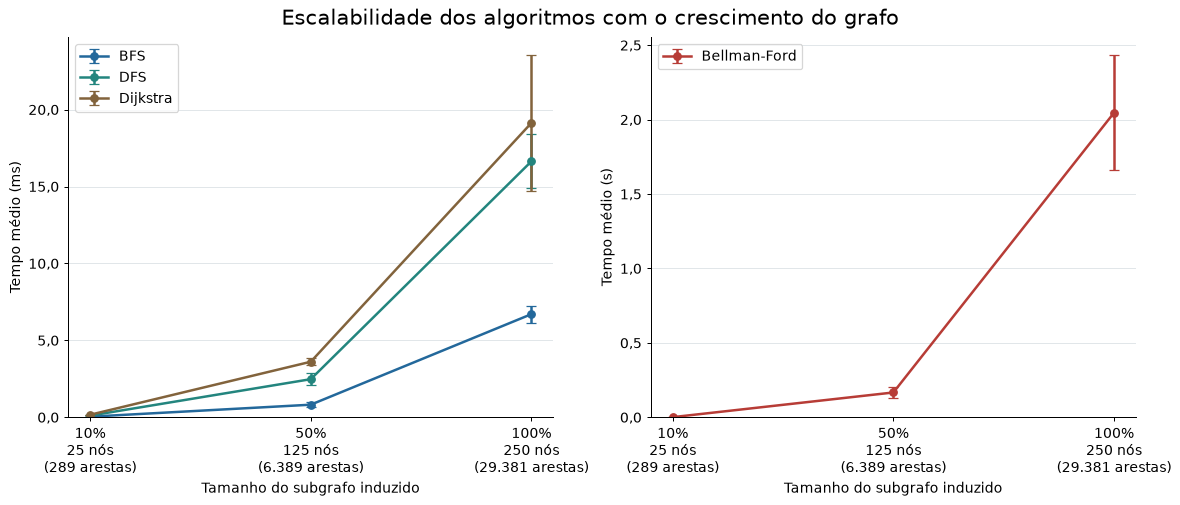

In [5]:
def escalabilidade(relatorio):
    grupos = defaultdict(list)
    
    for item in relatorio["escalabilidade"]:
        grupos[item["algoritmo"]].append(item)
    fig, eixos = plt.subplots(1, 2, figsize=(13, 5.5), layout="constrained")
    
    fig.suptitle("Escalabilidade dos algoritmos com o crescimento do grafo")
    pontos = []
    
    for item in grupos["BFS"]:
        arestas = rotulo_numero(item["n_arestas"])
        pontos.append(f'{item["fracao"]:.0%}\n{item["n_nos"]} nós\n({arestas} arestas)')

    series = (
        ("BFS", "BFS", AZUL),
        ("DFS", "DFS", VERDE),
        ("DIJKSTRA", "Dijkstra", "#82633c"),
        ("BELLMAN_FORD", "Bellman-Ford", VERMELHO),
    )
    for chave, nome, cor in series:
        if chave == "BELLMAN_FORD":
            ax = eixos[1]
            fator = 1000
        else:
            ax = eixos[0]
            fator = 1

        medias = []
        desvios = []
        
        for item in grupos[chave]:
            medias.append(item["media_ms"] / fator)
            desvios.append(item["desvio_ms"] / fator)

        ax.errorbar(
            pontos,
            medias,
            yerr=desvios,
            marker="o",
            capsize=4,
            linewidth=2,
            color=cor,
            label=nome,
        )
    for ax, unidade in zip(eixos, ("ms", "s")):
        ax.set(xlabel="Tamanho do subgrafo induzido", ylabel=f"Tempo médio ({unidade})",
               ylim=(0, None))
        formatar_eixo_decimal(ax, 1)
        ax.legend()
        grade(ax)
    
    mostrar(fig, "alg_02_escalabilidade")


escalabilidade(relatorio)

### Crescimento medido e custo das implementações

Entre a menor amostra e a rede completa, o total de nós sobe de 25 para 250, e o de arestas sobe de 289 para 29.381. Ou seja, os nós crescem 10 vezes e as arestas, cerca de 102 vezes. Comparamos os tempos no gráfico acima usando uma origem por algoritmo em cada tamanho.

| Algoritmo | Custo no pior caso | Como ler o crescimento |
|---|---|---|
| BFS | `O(V² + E)` nesta implementação | A busca percorre nós e arestas alcançados. Como a fila é uma lista, retirar o primeiro elemento com `pop(0)` também desloca os elementos restantes. |
| DFS | `O(V + E)` | A visita percorre as listas de adjacência e classifica as arestas. Nesta rede, o aumento das arestas pesa mais que o aumento dos nós. |
| Dijkstra | `O(V² + E)` | A rotina procura o menor custo por varredura dos nós abertos. Entre as amostras extremas, tanto `V²` quanto `E` crescem cerca de 100 vezes. |
| Bellman-Ford | `O(V × (V + E))` nesta implementação, dominado por `VE` na rede estudada | A rotina faz `V − 1` passadas e mais uma verificação. O produto `VE` aumenta cerca de mil vezes, e o Bellman-Ford tem o maior crescimento observado. |

Na execução de referência, da menor amostra para a rede completa, o tempo médio cresceu cerca de 161 vezes na BFS, 151 na DFS, 114 no Dijkstra e 1.613 no Bellman-Ford.

Com três tamanhos, essa comparação mostra tendências. A densidade, a origem e quantos nós são alcançados também mudam entre as amostras, e as menores medições são mais sensíveis ao ruído do cronômetro.

### Saltos e atrito nas cinco rotas

Um painel mostra o número de saltos e o outro mostra a soma do atrito. As barras hachuradas indicam as rotas do Dijkstra que passam por um par fraco.

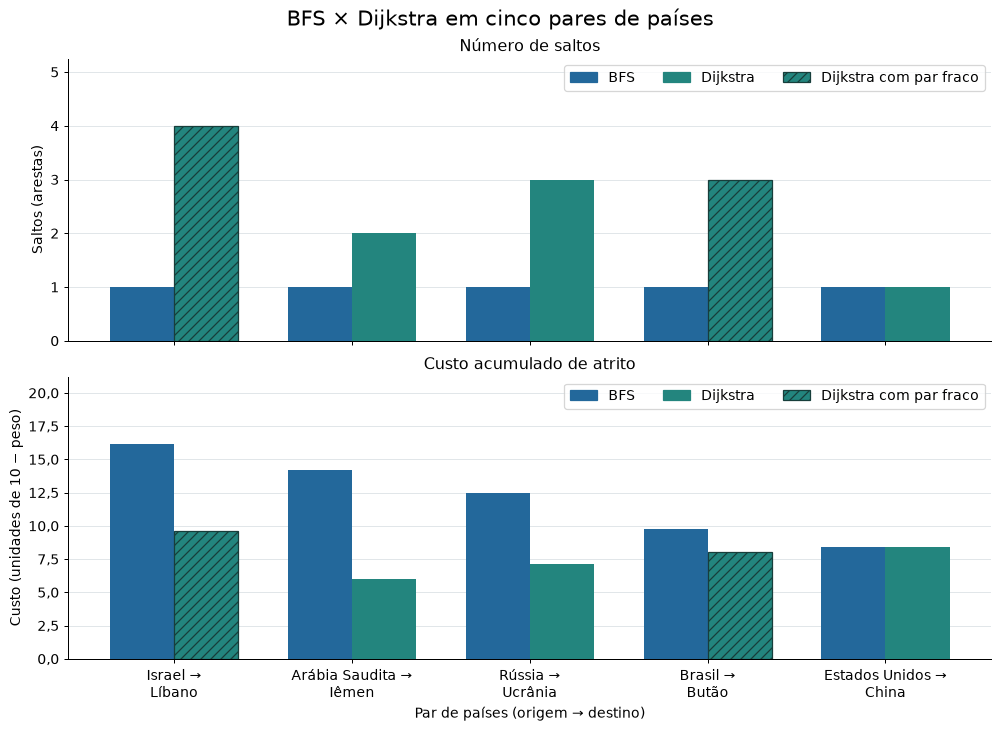

In [6]:
def comparar_rotas(relatorio):
    casos = relatorio["bfs_vs_dijkstra_5_pares"]
    fig, eixos = plt.subplots(2, 1, figsize=(11, 8), sharex=True, layout="constrained")
    fig.suptitle("BFS × Dijkstra em cinco pares de países")
    posicoes = range(len(casos))
    paineis = (
        (eixos[0], "saltos", "Número de saltos", "Saltos (arestas)"),
        (
            eixos[1],
            "custo_transformado",
            "Custo acumulado de atrito",
            "Custo (unidades de 10 − peso)",
        ),
    )

    for ax, campo, titulo, eixo in paineis:
        
        for algoritmo, nome, cor, deslocamento in (
            ("bfs", "BFS", AZUL, -0.18),
            ("dijkstra", "Dijkstra", VERDE, 0.18),
        ):
            posicoes_barras = []
            valores = []

            for posicao, caso in zip(posicoes, casos):
                posicoes_barras.append(posicao + deslocamento)
                valores.append(caso[algoritmo][campo])

            barras = ax.bar(
                posicoes_barras,
                valores,
                width=0.36,
                color=cor,
                label=nome,
            )
            for barra, caso in zip(barras, casos):
                if algoritmo == "dijkstra" and caso[algoritmo]["usa_par_fraco"]:
                    barra.set(hatch="///", edgecolor="#173e3b")
        legenda = [
            Patch(color=AZUL, label="BFS"),
            Patch(color=VERDE, label="Dijkstra"),
            Patch(
                facecolor=VERDE,
                edgecolor="#173e3b",
                hatch="///",
                label="Dijkstra com par fraco",
            ),
        ]
        ax.legend(handles=legenda, ncols=3)
        limite_inferior, limite_superior = ax.get_ylim()
        ax.set(
            title=titulo,
            ylabel=eixo,
            ylim=(0, limite_superior * 1.25),
        )
        if campo == "custo_transformado":
            formatar_eixo_decimal(ax, 1)
        grade(ax)

    rotulos = []
    
    for caso in casos:
        rotulos.append(nome_par(caso["origem"], caso["destino"], "\n"))
    
    eixos[-1].set_xticks(list(posicoes), rotulos)
    eixos[-1].set_xlabel("Par de países (origem → destino)")
    mostrar(fig, "alg_03_bfs_vs_dijkstra")


comparar_rotas(relatorio)

## 5. AVD exploratória da rede

In [7]:
arestas = ler_csv(DATASET / "arestas_paises.csv")
for item in arestas:
    item["peso"] = float(item["peso"])
    item["n_eventos"] = int(item["n_eventos"])
    item["anos_com_eventos"] = int(item["anos_com_eventos"])

### Graus de saída e de entrada

Cada ponto é um país. A diagonal indica graus iguais. O coeficiente de Pearson resume quanto os dois graus variam juntos.

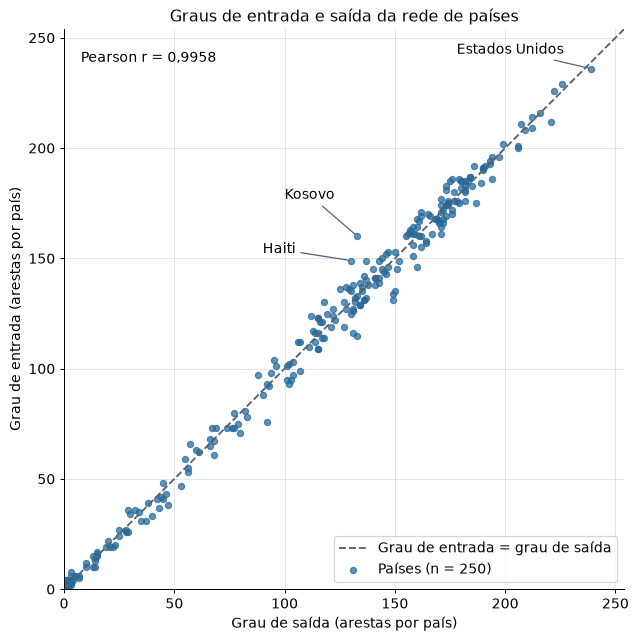

In [8]:
def graus(arestas):
    saida = Counter()
    entrada = Counter()
    
    for aresta in arestas:
        saida[aresta["origem"]] += 1
        entrada[aresta["destino"]] += 1

    paises = sorted(saida.keys() | entrada.keys())
    graus_saida = []
    graus_entrada = []
    
    for pais in paises:
        graus_saida.append(saida[pais])
        graus_entrada.append(entrada[pais])
    
    fig, ax = plt.subplots(figsize=(8, 7), layout="constrained")
    maior_saida = max(graus_saida)
    maior_entrada = max(graus_entrada)
    limite = max(maior_saida, maior_entrada) + 15
    
    ax.plot([0, limite], [0, limite], "--", color=CINZA, label="Grau de entrada = grau de saída")
    ax.scatter(
        graus_saida,
        graus_entrada,
        s=24,
        alpha=0.72,
        color=AZUL,
        label=f"Países (n = {len(paises)})",
    )

    rotulos = (
        ("United States", (-22, 12)),
        ("Kosovo", (-18, 30)),
        ("Haiti", (-44, 6)),
    )
    
    for pais, deslocamento in rotulos:
        ax.annotate(
            PAISES.get(pais, pais),
            (saida[pais], entrada[pais]),
            xytext=deslocamento,
            textcoords="offset points",
            ha="right",
            arrowprops={"arrowstyle": "-", "color": CINZA},
        )

    pearson = correlation(graus_saida, graus_entrada)
    ax.text(
        0.03,
        0.96,
        f"Pearson r = {rotulo_numero(pearson, 4)}",
        transform=ax.transAxes,
        va="top",
    )
    ax.set(xlabel="Grau de saída (arestas por país)", ylabel="Grau de entrada (arestas por país)",
           xlim=(0, limite), ylim=(0, limite), title="Graus de entrada e saída da rede de países")
    ax.set_aspect("equal")
    ax.legend(loc="lower right")
    
    grade(ax, "both")
    mostrar(fig, "avd_exp1_graus")


graus(arestas)

### Distribuição dos graus

Cada faixa agrupa 25 graus possíveis. As barras mostram, lado a lado, quantos países têm grau de entrada e de saída naquela faixa. Cada país conta uma vez na entrada e uma vez na saída.

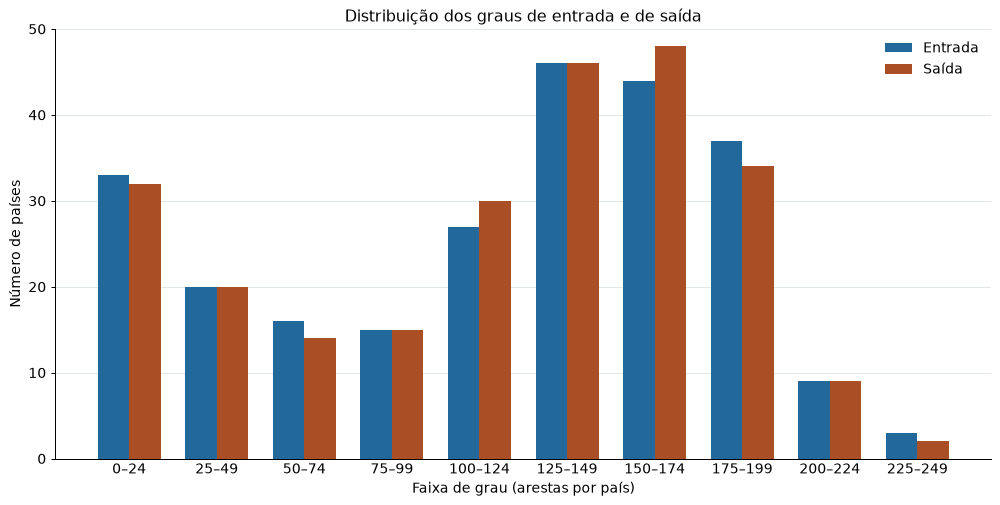

In [9]:
graus_entrada = Counter()
graus_saida = Counter()

for aresta in arestas:
    graus_saida[aresta["origem"]] += 1
    graus_entrada[aresta["destino"]] += 1

paises = sorted(graus_entrada.keys() | graus_saida.keys())
valores_entrada = []
valores_saida = []

for pais in paises:
    valores_entrada.append(graus_entrada[pais])
    valores_saida.append(graus_saida[pais])

largura_faixa = 25
frequencias_entrada = Counter()
frequencias_saida = Counter()

for grau in valores_entrada:
    faixa = grau // largura_faixa
    frequencias_entrada[faixa] += 1

for grau in valores_saida:
    faixa = grau // largura_faixa
    frequencias_saida[faixa] += 1

ultimo_grau = max(max(valores_entrada), max(valores_saida))
ultima_faixa = ultimo_grau // largura_faixa
rotulos_faixas = []
posicoes_entrada = []
posicoes_saida = []
contagens_entrada = []
contagens_saida = []

for faixa in range(ultima_faixa + 1):
    inicio = faixa * largura_faixa
    fim = inicio + largura_faixa - 1
    rotulos_faixas.append(f"{inicio}–{fim}")
    posicoes_entrada.append(faixa - 0.18)
    posicoes_saida.append(faixa + 0.18)
    contagens_entrada.append(frequencias_entrada[faixa])
    contagens_saida.append(frequencias_saida[faixa])

fig, ax = plt.subplots(figsize=(11, 5.5), layout="constrained")
ax.bar(posicoes_entrada, contagens_entrada, width=0.36, color=AZUL, label="Entrada")
ax.bar(posicoes_saida, contagens_saida, width=0.36, color="#a94e25", label="Saída")
ax.set_xticks(range(len(rotulos_faixas)), rotulos_faixas)

maior_contagem = max(max(contagens_entrada), max(contagens_saida))
teto = math.ceil(maior_contagem / 10) * 10
ax.set_yticks(range(0, teto + 1, 10))
ax.set(
    title="Distribuição dos graus de entrada e de saída",
    xlabel="Faixa de grau (arestas por país)",
    ylabel="Número de países",
    ylim=(0, teto),
)
ax.tick_params(axis="x", length=0)
ax.legend(frameon=False)

grade(ax)
mostrar(fig, "avd_exp1_distribuicao_graus")

### Distribuição dos pesos

O histograma agrupa os pesos em faixas de 0,5. As cores separam os pesos negativos dos demais e a linha marca a mediana.

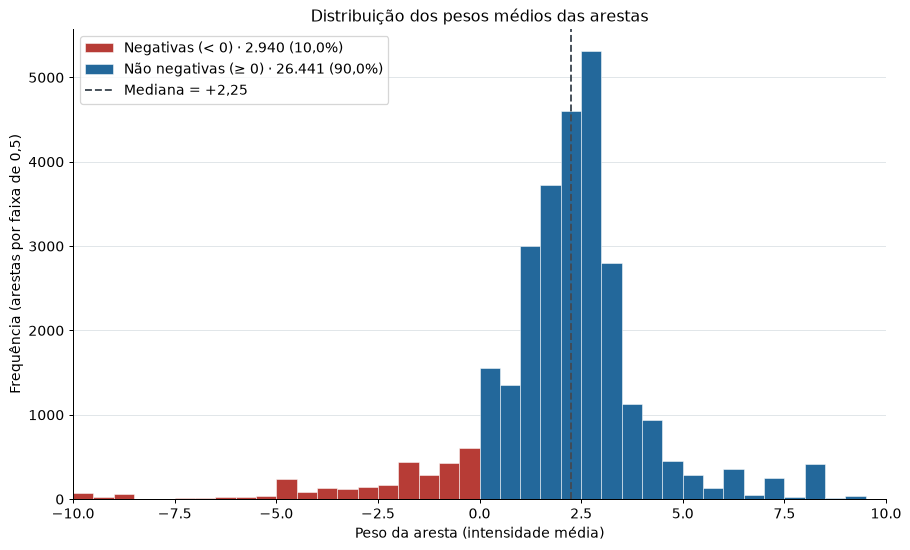

In [10]:
def histograma_pesos(arestas):
    pesos = []
    negativas = []
    demais = []

    for aresta in arestas:
        peso = aresta["peso"]
        pesos.append(peso)

        if peso < 0:
            negativas.append(peso)
        else:
            demais.append(peso)

    limites_negativos = []

    for passo in range(-20, 1):
        limites_negativos.append(passo / 2)

    limites_nao_negativos = []

    for passo in range(21):
        limites_nao_negativos.append(passo / 2)

    mediana = median(pesos)
    fig, ax = plt.subplots(figsize=(10, 6), layout="constrained")

    for grupo, bins, cor, nome in (
        (negativas, limites_negativos, VERMELHO, "Negativas (< 0)"),
        (demais, limites_nao_negativos, AZUL, "Não negativas (≥ 0)"),
    ):
        quantidade = rotulo_numero(len(grupo))
        percentual = rotulo_numero(100 * len(grupo) / len(pesos), 1)
        legenda = f"{nome} · {quantidade} ({percentual}%)"
        ax.hist(grupo, bins=bins, color=cor, edgecolor="white", linewidth=0.4, label=legenda)

    rotulo_mediana = rotulo_numero(mediana, 2)

    ax.axvline(
        mediana,
        color=NEUTRO,
        linestyle="--",
        label=f"Mediana = +{rotulo_mediana}",
    )

    ax.set(
        title="Distribuição dos pesos médios das arestas",
        xlim=(-10, 10),
        xlabel="Peso da aresta (intensidade média)",
        ylabel="Frequência (arestas por faixa de 0,5)",
    )

    ax.legend(loc="upper left")
    
    grade(ax)
    mostrar(fig, "avd_exp2_histograma_peso")


histograma_pesos(arestas)

### Volume de eventos e peso médio

Usamos escala logarítmica no volume para mostrar arestas com poucos e muitos eventos no mesmo eixo. A cor indica em quantos anos o par teve eventos.

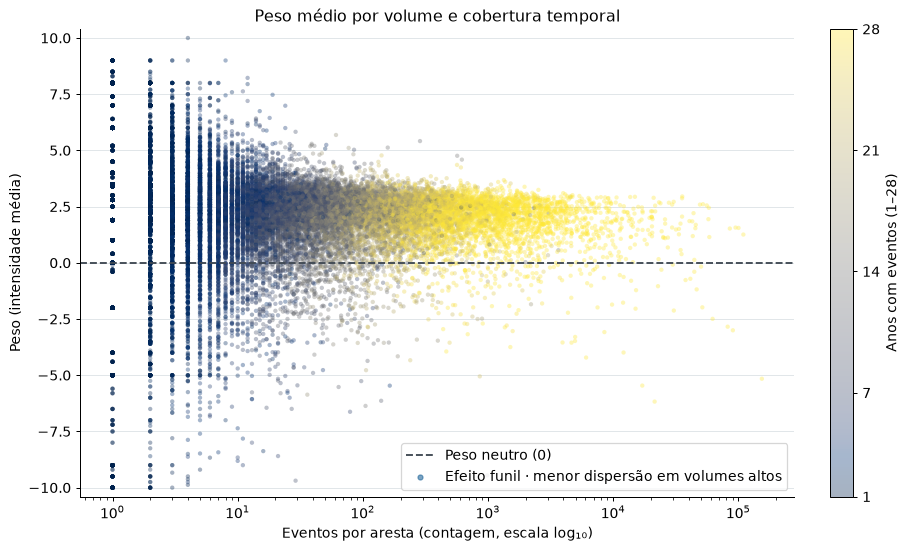

In [11]:
def eventos_peso(arestas):
    fig, ax = plt.subplots(figsize=(10, 6), layout="constrained")
    volumes = []
    pesos = []
    cobertura = []

    for aresta in arestas:
        volumes.append(aresta["n_eventos"])
        pesos.append(aresta["peso"])
        cobertura.append(aresta["anos_com_eventos"])

    pontos = ax.scatter(
        volumes,
        pesos,
        c=cobertura,
        cmap="cividis",
        vmin=1,
        vmax=28,
        s=12,
        alpha=0.35,
        linewidths=0,
    )
    fig.colorbar(pontos, ax=ax, label="Anos com eventos (1–28)", ticks=[1, 7, 14, 21, 28])
    
    ax.axhline(0, color=NEUTRO, linestyle="--", label="Peso neutro (0)")
    ax.scatter([], [], color=AZUL, s=16, alpha=0.6,
               label="Efeito funil · menor dispersão em volumes altos")
    ax.set(
        xscale="log",
        ylim=(-10.4, 10.4),
        title="Peso médio por volume e cobertura temporal",
        xlabel="Eventos por aresta (contagem, escala log₁₀)",
        ylabel="Peso (intensidade média)",
    )
    ax.legend(loc="lower right")
    
    grade(ax)
    mostrar(fig, "avd_exp3_eventos_vs_peso")


eventos_peso(arestas)

## 6. Intensidade dos eventos

Aqui usamos os eventos brutos para comparar a intensidade por setor de origem, veículo e local. Para o gráfico por ano, lemos a série do resumo anual do projeto.

Lemos os TSVs linha por linha e guardamos a contagem e a soma de cada grupo. Corrigimos os zeros que se perderam nos códigos CAMEO e pulamos os códigos sem família válida. Cada setor conta uma vez por evento. Tratamos `NULL` como campo vazio e agrupamos os veículos sem identificação em **Desconhecido**.

In [12]:
PADRAO_ANO = re.compile(r"^(?:events|eventos)[._-]?(\d{4})", re.IGNORECASE)

CAMPOS = ("CAMEO Code", "Intensity", "Source Sectors", "Publisher",
          "Source Country", "Target Country", "Country")

FAMILIAS = (
    "Fazer declaração pública", "Fazer apelo", "Expressar intenção de cooperar",
    "Consultar", "Engajar-se em cooperação diplomática", "Engajar-se em cooperação material",
    "Fornecer ajuda", "Ceder", "Investigar", "Exigir", "Desaprovar", "Rejeitar",
    "Ameaçar", "Protestar", "Demonstrar força militar", "Reduzir relações",
    "Coagir", "Agredir", "Combater", "Usar violência em massa não convencional",
)

NOMES_FAMILIAS = {}

for numero, nome in enumerate(FAMILIAS, 1):
    codigo_familia = f"{numero:02d}"
    NOMES_FAMILIAS[codigo_familia] = nome


def normalizar_cameo(codigo):
    
    if not codigo.isascii() or not codigo.isdigit():
        return None
    
    if len(codigo) == 2:
        codigo = codigo.zfill(3)
    elif len(codigo) == 3 and codigo[0] in "23456789" and not codigo.startswith("20"):
        codigo = codigo.zfill(4)
    familia = codigo[:2]
    
    if len(codigo) in (3, 4) and familia in NOMES_FAMILIAS:
        return familia
    
    return None


def limpar_ausencia(valor):
    valor = valor.strip()
    
    if valor == "NULL":
        return ""
    
    return valor


def tipo_localizacao(origem, destino, local):
    
    if not origem or not destino:
        return "sem_pais_ator"
    
    if origem == destino:
    
        if local == origem:
            return "domestico"
    
        return "domestico_no_exterior"
    
    if local == origem:
        return "bilateral_na_origem"
    
    if local == destino:
        return "bilateral_no_destino"
    
    return "bilateral_terceiro_pais"


def acumular(grupos, chave, intensidade):
    
    if chave not in grupos:
        grupos[chave] = [0, 0.0]

    grupo = grupos[chave]
    grupo[0] += 1
    grupo[1] += intensidade


def ordem_por_frequencia(grupo):
    chave, totais = grupo
    contagem = totais[0]
    
    return -contagem, chave


def medias_por_frequencia(grupos, campo):
    ordenados = sorted(grupos.items(), key=ordem_por_frequencia)
    medias = []
    
    for chave, totais in ordenados:
        contagem, soma = totais
        media = soma / contagem
        medias.append({
            campo: chave,
            "media_intensidade": media,
        })
    
    return medias


def preparar_intensidades(pasta_raw):
    arquivos_por_ano = defaultdict(list)
    
    for arquivo in sorted(pasta_raw.glob("*.tab")):
        correspondencia = PADRAO_ANO.match(arquivo.name)
    
        if correspondencia:
            ano = int(correspondencia[1])
            arquivos_por_ano[ano].append(arquivo)

    anos = range(1995, 2023)
    faltam = []
    
    for ano in anos:
    
        if ano not in arquivos_por_ano:
            faltam.append(ano)
    
    if faltam:
        raise FileNotFoundError(f"Arquivos anuais ausentes em {pasta_raw}: {faltam}")

    cameo = {}
    intensidades_por_familia = defaultdict(set)
    setores = {}
    veiculos = {}
    locais = {}
    # [IA] ChatGPT – Agrupar a intensidade dos eventos pelo país de ocorrência para o mapa.
    paises_evento = {}

    total = 0
    normalizados = 0
    invalidos = 0
    
    for ano in anos:
    
        for arquivo in arquivos_por_ano[ano]:
    
            with arquivo.open(encoding="utf-8-sig", newline="") as entrada:
                leitor = csv.reader(entrada, delimiter="\t")
                cabecalho = []
    
                for campo in next(leitor, []):
                    cabecalho.append(campo.strip())

                faltantes = []
    
                for campo in CAMPOS:
    
                    if campo not in cabecalho:
                        faltantes.append(campo)

                if faltantes:
                    raise ValueError(f"{arquivo.name} sem colunas obrigatórias: {faltantes}")

                indice_cameo = cabecalho.index("CAMEO Code")
                indice_intensidade = cabecalho.index("Intensity")
                indice_setores = cabecalho.index("Source Sectors")
                indice_veiculo = cabecalho.index("Publisher")
                indice_origem = cabecalho.index("Source Country")
                indice_destino = cabecalho.index("Target Country")
                indice_local = cabecalho.index("Country")

                for linha in leitor:
    
                    if not linha:
                        continue
    
                    try:
                        intensidade = float(linha[indice_intensidade])
                    except ValueError:
                        continue
    
                    if not math.isfinite(intensidade):
                        continue
    
                    total += 1

                    codigo = linha[indice_cameo].strip()
                    familia = normalizar_cameo(codigo)
    
                    if familia is None:
                        invalidos += 1
                    else:
    
                        if familia != codigo[:2]:
                            normalizados += 1
    
                        acumular(cameo, familia, intensidade)
                        intensidades_por_familia[familia].add(intensidade)

                    rotulos = set()
    
                    for rotulo in linha[indice_setores].split(","):
                        setor = limpar_ausencia(rotulo)
    
                        if setor:
                            rotulos.add(setor)

                    if not rotulos:
                        rotulos.add("Não classificado")

                    for setor in rotulos:
                        acumular(setores, setor, intensidade)

                    veiculo = linha[indice_veiculo].strip()
    
                    if not veiculo or veiculo.lower() == "unknown":
                        veiculo = "Desconhecido"
    
                    acumular(veiculos, veiculo, intensidade)

                    origem = limpar_ausencia(linha[indice_origem])
                    destino = limpar_ausencia(linha[indice_destino])
                    local = limpar_ausencia(linha[indice_local])
    
                    contexto = tipo_localizacao(origem, destino, local)
                    acumular(locais, contexto, intensidade)

                    if local:
                        acumular(paises_evento, local, intensidade)

    resumo_cameo = []
    
    for familia, nome in NOMES_FAMILIAS.items():
        contagem, soma = cameo.get(familia, (0, 0.0))
        media = 0.0
    
        if contagem:
            media = soma / contagem
    
        resumo_cameo.append({
            "familia": familia,
            "nome_familia": nome,
            "media_intensidade": media,
            "intensidades_observadas": sorted(intensidades_por_familia[familia]),
        })
    
    dados = {
        "cameo": resumo_cameo,
        "setor": medias_por_frequencia(setores, "setor"),
        "veiculo": medias_por_frequencia(veiculos, "veiculo"),
        "localizacao": medias_por_frequencia(locais, "tipo_localizacao"),
        "paises_evento": paises_evento,
    }
    print(f"{total:,} eventos com intensidade | {normalizados:,} códigos CAMEO normalizados | "
          f"{invalidos:,} códigos ignorados")
    return dados


intensidades = preparar_intensidades(DATASET / "raw")

20,188,517 eventos com intensidade | 1,377,818 códigos CAMEO normalizados | 27 códigos ignorados


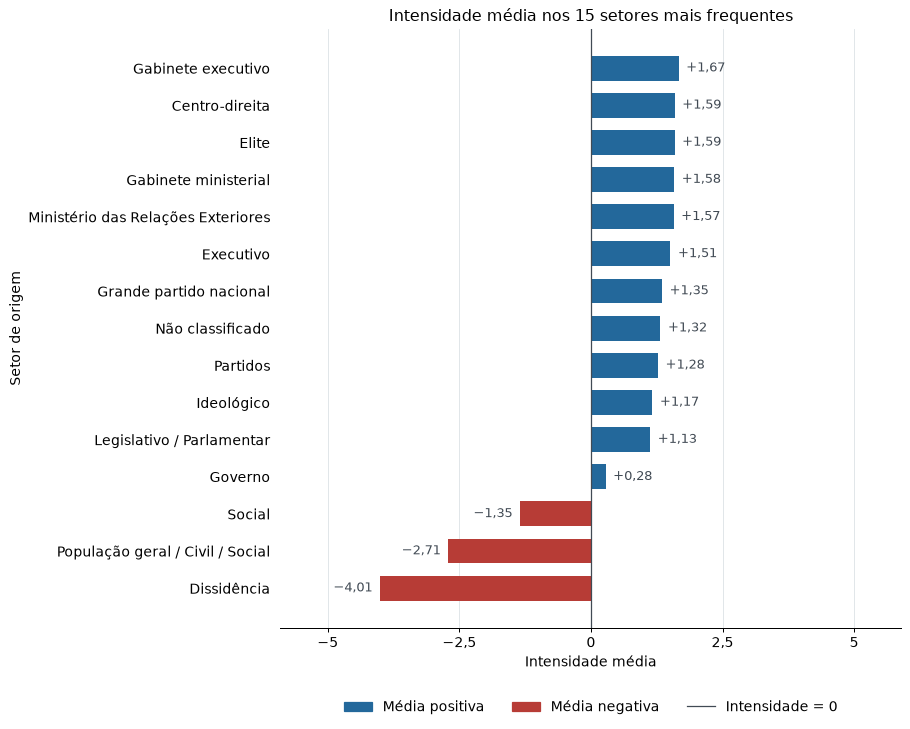

In [13]:
setores_frequentes = intensidades["setor"][:15]
setores = series_intensidade(setores_frequentes, "setor", SETORES)

fig, ax = plt.subplots(figsize=(10, 8), layout="constrained")
barras_intensidade(ax, setores, "Intensidade média nos 15 setores mais frequentes", "Setor de origem")
ax.legend(
    handles=legenda_intensidade(),
    loc="upper center",
    bbox_to_anchor=(0.5, -0.1),
    ncols=3,
    frameon=False,
)
mostrar(fig, "avd_exp4_setores")

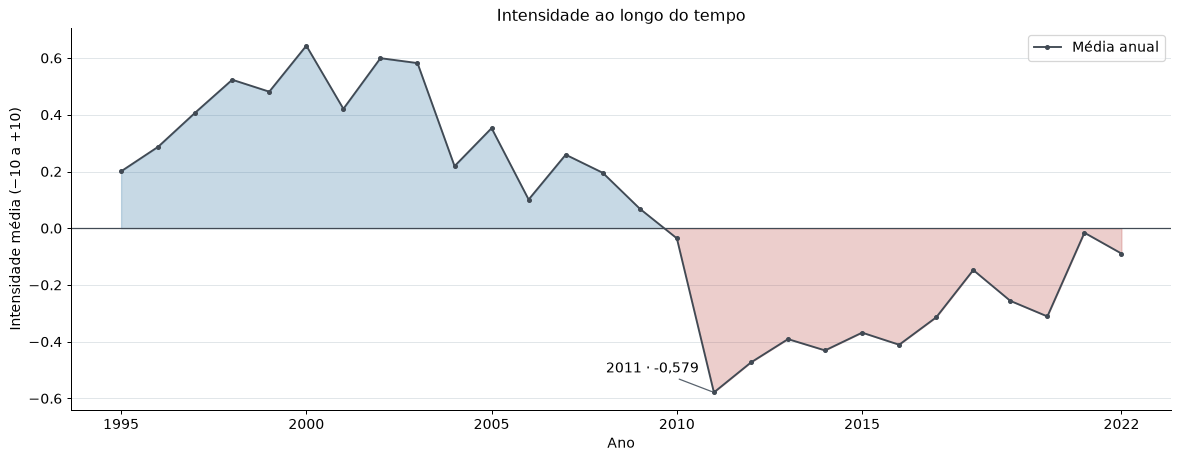

In [14]:
resumo_anos = ler_csv(PROCESSADO / "resumo_anos.csv")
# [IA] ChatGPT – Ajustar as dimensões da figura de intensidade por ano.
fig, ax = plt.subplots(figsize=(13, 5), layout="constrained")

anos = []
medias = []
faixa_nao_negativa = []
faixa_negativa = []
for item in resumo_anos:
    ano = int(item["ano"])
    media = float(item["intensidade_media"])
    anos.append(ano)
    medias.append(media)
    faixa_nao_negativa.append(media >= 0)
    faixa_negativa.append(media < 0)

ax.plot(anos, medias, marker="o", markersize=3, color=NEUTRO, label="Média anual")
ax.fill_between(
    anos, 0, medias, where=faixa_nao_negativa, interpolate=True, alpha=0.25, color=AZUL
)
ax.fill_between(
    anos, 0, medias, where=faixa_negativa, interpolate=True, alpha=0.25, color=VERMELHO
)
ax.axhline(0, color=NEUTRO, linewidth=1)

menor_media = min(medias)
indice_menor_media = medias.index(menor_media)
ano_da_menor_media = anos[indice_menor_media]
rotulo_menor_media = f"{ano_da_menor_media} · {rotulo_numero(menor_media, 3)}"
ax.annotate(
    rotulo_menor_media,
    (ano_da_menor_media, menor_media),
    xytext=(-12, 16),
    textcoords="offset points",
    ha="right",
    arrowprops={"arrowstyle": "-", "color": CINZA},
)
ax.set(
    title="Intensidade ao longo do tempo",
    xlabel="Ano",
    ylabel="Intensidade média (−10 a +10)",
)
ax.set_xticks([1995, 2000, 2005, 2010, 2015, 2022])
ax.legend(loc="upper right")
grade(ax)
mostrar(fig, "avd_exp4_ano")

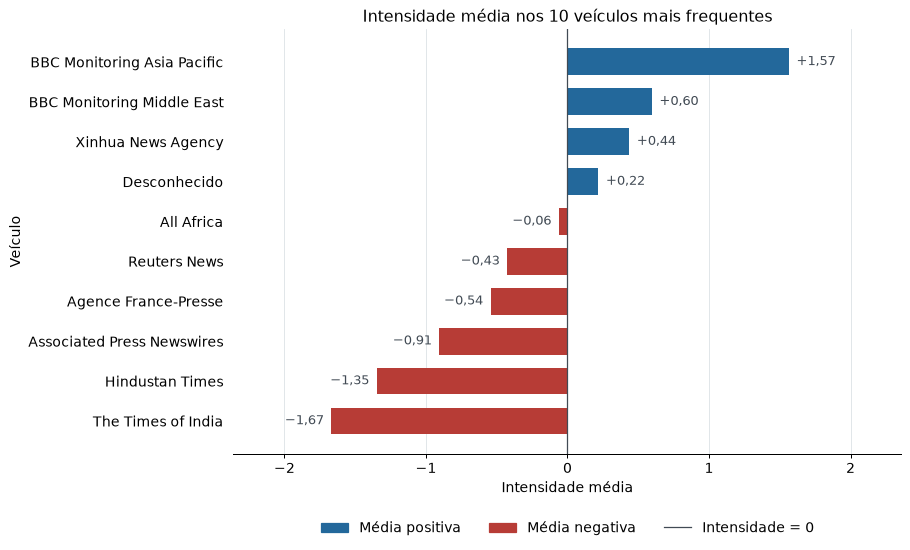

In [15]:
veiculos_frequentes = intensidades["veiculo"][:10]
veiculos = series_intensidade(veiculos_frequentes, "veiculo", {})

fig, ax = plt.subplots(figsize=(10, 6), layout="constrained")
barras_intensidade(ax, veiculos, "Intensidade média nos 10 veículos mais frequentes", "Veículo")
ax.legend(
    handles=legenda_intensidade(),
    loc="upper center",
    bbox_to_anchor=(0.5, -0.13),
    ncols=3,
    frameon=False,
)
mostrar(fig, "avd_exp4_veiculos")

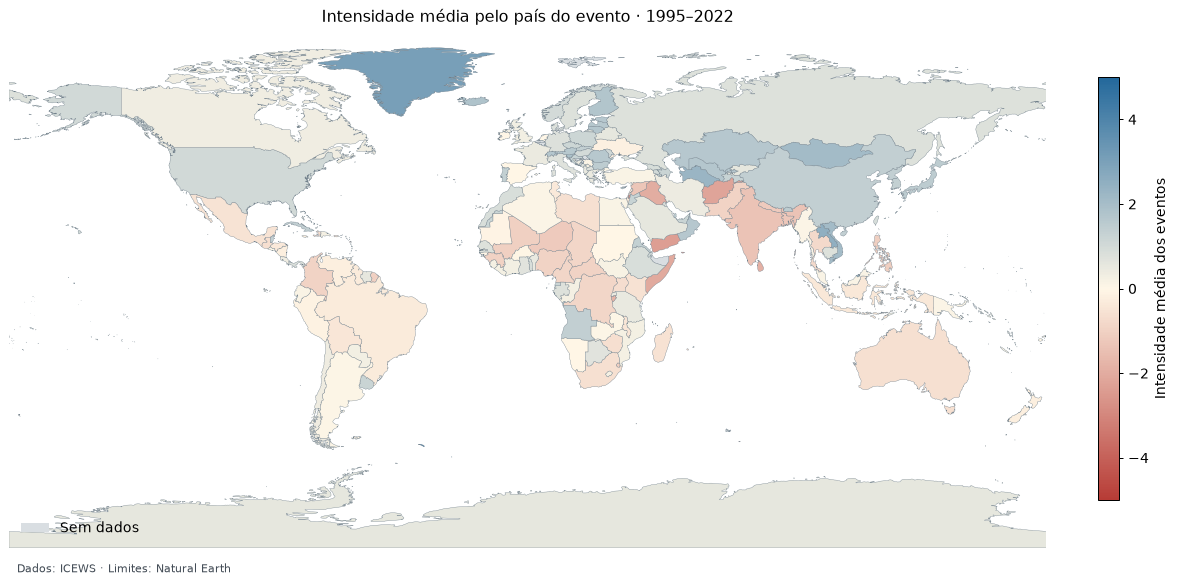

In [16]:
# [IA] ChatGPT – Implementar o mapa por país com limites da Natural Earth e atualizar a descrição do gráfico em graficos.json.
import unicodedata

from matplotlib.cm import ScalarMappable
from matplotlib.colors import LinearSegmentedColormap, Normalize
from matplotlib.patches import PathPatch
from matplotlib.path import Path as CaminhoMatplotlib


def chave_pais(nome):
    texto = unicodedata.normalize("NFKD", nome.casefold())
    return "".join(caractere for caractere in texto if caractere.isalnum())


def mapa_intensidade(paises_evento):
    caminho = DATASET / "ne_50m_admin_0_map_units.geojson"
    feicoes = json.loads(caminho.read_text(encoding="utf-8"))["features"]
    nomes = {}
    for feicao in feicoes:
        propriedades = feicao["properties"]
        for nome in propriedades["nomes"]:
            nomes[chave_pais(nome)] = propriedades["codigo"]

    equivalencias = {
        "Cook Island": "COK",
        "Democratic Republic of Congo": "COD",
        "Holy See": "VAT",
        "Moldova, Republic of": "MDA",
        "Occupied Palestinian Territory": "PSE",
        "Swaziland": "SWZ",
        "the former Yugoslav Republic of": "MKD",
        "the former Yugoslav Republic of Macedonia": "MKD",
        "CuraÃ§ao": "CUW",
    }
    for nome, codigo in equivalencias.items():
        nomes[chave_pais(nome)] = codigo

    totais = defaultdict(lambda: [0, 0.0])
    for nome, (contagem, soma) in paises_evento.items():
        codigo = nomes.get(chave_pais(nome))
        if codigo is not None:
            totais[codigo][0] += contagem
            totais[codigo][1] += soma

    medias = {codigo: soma / contagem for codigo, (contagem, soma) in totais.items()}
    if not medias:
        raise ValueError("Nenhum país dos eventos corresponde à base do mapa.")

    amplitude = max(1, math.ceil(max(abs(valor) for valor in medias.values())))
    escala = Normalize(-amplitude, amplitude)
    cores = LinearSegmentedColormap.from_list("intensidade_icews", [VERMELHO, "#fff7e7", AZUL])
    cor_sem_dados = "#d9dee2"

    fig, ax = plt.subplots(figsize=(13, 6.5), layout="constrained")
    for feicao in feicoes:
        codigo = feicao["properties"]["codigo"]
        geometria = feicao["geometry"]
        poligonos = geometria["coordinates"]
        if geometria["type"] == "Polygon":
            poligonos = [poligonos]

        cor = cores(escala(medias[codigo])) if codigo in medias else cor_sem_dados
        for poligono in poligonos:
            aneis = [CaminhoMatplotlib(anel, closed=True) for anel in poligono]
            contorno = CaminhoMatplotlib.make_compound_path(*aneis)
            ax.add_patch(PathPatch(contorno, facecolor=cor, edgecolor="#71808b", linewidth=0.28))

    fig.colorbar(
        ScalarMappable(norm=escala, cmap=cores), ax=ax, shrink=0.74,
        label="Intensidade média dos eventos"
    )
    ax.legend(handles=[Patch(facecolor=cor_sem_dados, label="Sem dados")],
              loc="lower left", frameon=False)
    ax.set(title="Intensidade média pelo país do evento · 1995–2022",
           xlim=(-180, 180), ylim=(-90, 90), aspect="equal")
    ax.set_axis_off()
    fig.text(0.01, 0.01, "Dados: ICEWS · Limites: Natural Earth", fontsize=9, color=NEUTRO)
    mostrar(fig, "avd_exp4_localizacao")


mapa_intensidade(intensidades["paises_evento"])

## 7. Dados faltantes

O mapa de calor compara a ausência de dados em dez campos. Cada célula mostra a média das correlações anuais de Pearson. Anos em que um dos campos não varia ficam fora da média daquele par. A diagonal vale 1 e as cores usam a mesma escala de −1 a +1.

As ausências têm explicações diferentes. Um ator supranacional pode não ter um país único. Setores podem faltar quando a classificação do ator está incompleta, e campos como cidade e província dependem do detalhamento da geocodificação. A associação entre ausências é compatível com essas hipóteses, mas não determina a causa. Mantemos os registros nas análises em que os campos necessários estão disponíveis. Para montar as arestas entre países, usamos os eventos com países de origem e destino identificados, sem atribuir países aos casos faltantes.

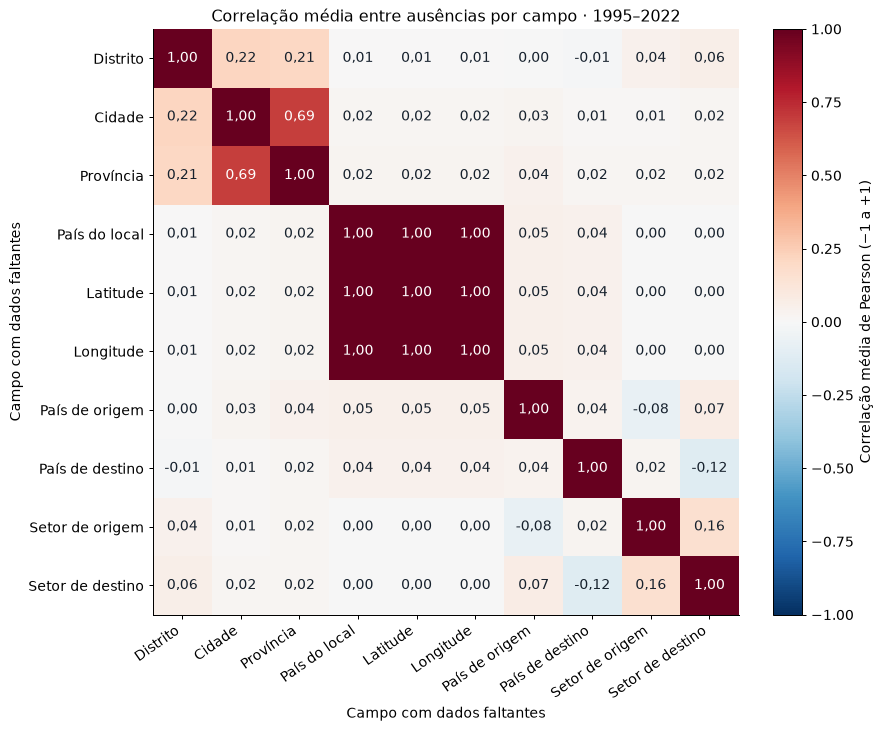

In [17]:
def heatmap_ausencias(dados):
    colunas = {
        "District": "Distrito",
        "City": "Cidade",
        "Province": "Província",
        "Country": "País do local",
        "Latitude": "Latitude",
        "Longitude": "Longitude",
        "Source Country": "País de origem",
        "Target Country": "País de destino",
        "Source Sectors": "Setor de origem",
        "Target Sectors": "Setor de destino",
    }
    pares = defaultdict(list)
    for item in dados:
        coluna_a = item["coluna_a"]
        coluna_b = item["coluna_b"]
        correlacao = item["correlacao"]
        if coluna_a in colunas and coluna_b in colunas and correlacao:
            pares[coluna_a, coluna_b].append(float(correlacao))

    matriz = []
    for coluna_a in colunas:
        linha = []
        for coluna_b in colunas:
            correlacoes = pares.get((coluna_a, coluna_b), [])
            if coluna_a == coluna_b:
                valor = 1.0
            elif correlacoes:
                valor = mean(correlacoes)
            else:
                valor = float("nan")
            linha.append(valor)
        matriz.append(linha)
    fig, ax = plt.subplots(figsize=(10, 8), layout="constrained")
    imagem = ax.imshow(matriz, cmap="RdBu_r", vmin=-1, vmax=1)
    fig.colorbar(imagem, ax=ax, label="Correlação média de Pearson (−1 a +1)")
    ax.set_xticks(range(len(colunas)), colunas.values(), rotation=35, ha="right")
    ax.set_yticks(range(len(colunas)), colunas.values())
    for i, linha in enumerate(matriz):
        for j, valor in enumerate(linha):
            rotulo = "—"
            if math.isfinite(valor):
                rotulo = rotulo_numero(valor, 2)

            cor = "#16212d"
            if abs(valor) >= 0.65:
                cor = "white"

            ax.text(j, i, rotulo, ha="center", va="center", color=cor)
    ax.set(title="Correlação média entre ausências por campo · 1995–2022",
           xlabel="Campo com dados faltantes", ylabel="Campo com dados faltantes")
    mostrar(fig, "avd_apoio_heatmap_ausencias")


correlacao_ausencias = ler_csv(PROCESSADO / "correlacao_nulos_por_ano.csv")
heatmap_ausencias(correlacao_ausencias)

## 8. AVD explanatória

### Pares de baixo volume e casos de hostilidade

A faixa mostra as arestas de um único evento. Os pontos vermelhos destacam pares com pelo menos mil eventos e peso abaixo de −2. A Guiana e Curaçao aparecem no ciclo encontrado pelo Bellman-Ford.

Das 63 arestas com peso −10, 55 têm apenas um evento. O valor −10 é válido na escala ICEWS. Mantemos essas arestas no grafo principal e repetimos a comparação sem os pares de evento único para medir quanto os resultados dependem deles.

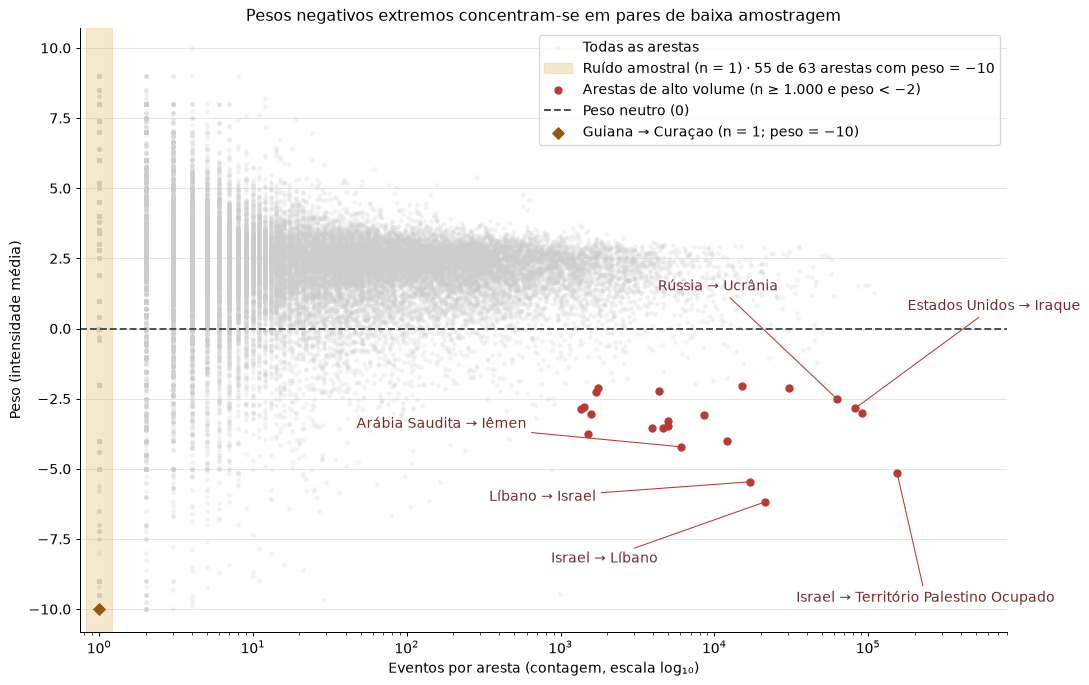

In [18]:
def nucleos(arestas):
    volumes = []
    pesos = []
    volumes_estruturais = []
    pesos_estruturais = []
    n_extremos = 0
    n_fracas = 0
    pares = {}

    for aresta in arestas:
        volume = aresta["n_eventos"]
        peso = aresta["peso"]
        volumes.append(volume)
        pesos.append(peso)

        par = (aresta["origem"], aresta["destino"])
        pares[par] = aresta

        if peso == -10:
            n_extremos += 1
            if volume == 1:
                n_fracas += 1

        if volume >= 1000 and peso < -2:
            volumes_estruturais.append(volume)
            pesos_estruturais.append(peso)

    fig, ax = plt.subplots(figsize=(12, 7.5), layout="constrained")
    ax.scatter(
        volumes,
        pesos,
        color="#cccccc",
        alpha=0.25,
        s=14,
        linewidths=0,
        label="Todas as arestas",
    )
    ax.axvspan(
        0.82,
        1.21,
        color="#e5be75",
        alpha=0.35,
        label=f"Ruído amostral (n = 1) · {n_fracas} de {n_extremos} arestas com peso = −10",
    )
    ax.scatter(
        volumes_estruturais,
        pesos_estruturais,
        color=VERMELHO,
        s=32,
        label="Arestas de alto volume (n ≥ 1.000 e peso < −2)",
    )
    ax.axhline(0, color=NEUTRO, linestyle="--", label="Peso neutro (0)")
    atipico = pares["Guyana", "Curaçao"]
    ax.scatter(atipico["n_eventos"], atipico["peso"], color="#92580c", marker="D", s=42, zorder=4,
               label="Guiana → Curaçao (n = 1; peso = −10)")
    rotulos = (
        ("Saudi Arabia", "Yemen", (600, -3.4), "right"),
        ("Lebanon", "Israel", (1700, -6.0), "right"),
        ("Israel", "Lebanon", (4300, -8.2), "right"),
        ("Israel", "Occupied Palestinian Territory", (34000, -9.6), "left"),
        ("Russian Federation", "Ukraine", (26000, 1.5), "right"),
        ("United States", "Iraq", (180000, 0.8), "left"),
    )
    for origem, destino, texto, alinhamento in rotulos:
        item = pares[origem, destino]
        ax.annotate(nome_par(origem, destino), (item["n_eventos"], item["peso"]), xytext=texto,
                    ha=alinhamento, va="center", color="#762b29",
                    arrowprops={"arrowstyle": "-", "color": VERMELHO, "linewidth": 0.85})
    ax.set(
        title="Pesos negativos extremos concentram-se em pares de baixa amostragem",
        xscale="log",
        xlim=(0.75, 800000),
        ylim=(-10.8, 10.7),
        xlabel="Eventos por aresta (contagem, escala log₁₀)",
        ylabel="Peso (intensidade média)",
    )
    ax.legend(loc="upper right")
    grade(ax)
    mostrar(fig, "avd_explanatorio1_nucleos")


nucleos(arestas)

### Intensidade por contexto e setor

Os dois painéis usam a mesma escala para comparar as médias em torno de zero. Mostramos os seis contextos geográficos e os dez setores escolhidos no roteiro. Polícia, organização intergovernamental e forças armadas ficaram nas posições 16 a 18 por frequência.

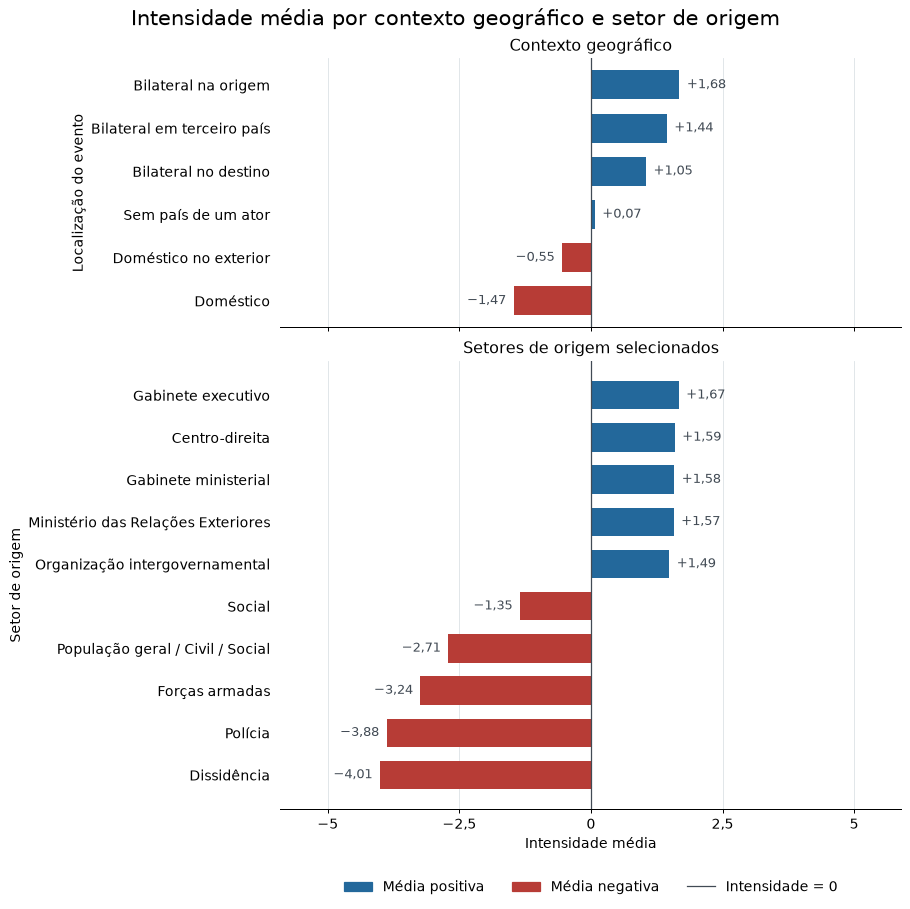

In [19]:
def domestico_setor(intensidades):
    locais = series_intensidade(intensidades["localizacao"], "tipo_localizacao", LOCAIS)
    selecionados = {
        "Executive Office",
        "Center Right",
        "Cabinet",
        "International Government Organization",
        "Foreign Ministry",
        "Dissident",
        "Police",
        "Military",
        "General Population / Civilian / Social",
        "Social",
    }
    dados_setores = []
    for item in intensidades["setor"]:
        if item["setor"] in selecionados:
            dados_setores.append(item)

    setores = series_intensidade(dados_setores, "setor", SETORES)

    maior_magnitude = 0
    for rotulo, media in locais + setores:
        maior_magnitude = max(maior_magnitude, abs(media))
    amplitude = max(1, math.ceil(maior_magnitude))

    fig, eixos = plt.subplots(
        2, 1, figsize=(10, 10), layout="constrained", sharex=True,
        gridspec_kw={"height_ratios": [6, 10]},
    )
    fig.suptitle("Intensidade média por contexto geográfico e setor de origem")

    barras_intensidade(
        eixos[0], locais, "Contexto geográfico", "Localização do evento", amplitude=amplitude
    )
    eixos[0].set_xlabel("")
    barras_intensidade(
        eixos[1], setores, "Setores de origem selecionados", "Setor de origem", amplitude=amplitude
    )
    eixos[1].legend(
        handles=legenda_intensidade(),
        loc="upper center",
        bbox_to_anchor=(0.5, -0.13),
        ncols=3,
        frameon=False,
    )
    mostrar(fig, "avd_explanatorio2_domestico_setor")


domestico_setor(intensidades)

## 9. Discussão dos resultados

### Resposta à pergunta de pesquisa

**Caminhos.** A tabela mostra os países e territórios nas rotas de menor atrito encontradas pelo Dijkstra para os cinco pares estudados. O custo de cada ligação vem da intensidade média das ações entre seus dois extremos.

| Par estudado | Rota de menor atrito no grafo completo |
|---|---|
| Israel → Líbano | Israel → Macau → Armênia → Camboja → Líbano |
| Arábia Saudita → Iêmen | Arábia Saudita → Fiji → Iêmen |
| Rússia → Ucrânia | Rússia → Antígua e Barbuda → São Vicente e Granadinas → Ucrânia |
| Brasil → Butão | Brasil → Dominica → Croácia → Butão |
| Estados Unidos → China | Estados Unidos → China |

Em quatro dos cinco pares, a rota de menor atrito teve mais saltos que a da BFS. De Israel ao Líbano, o custo caiu de 16,17 em um salto para 9,58 em quatro. Ao retirar os pares de um único evento, Israel → Líbano passou por Trinidad e Tobago (dois saltos, custo 9,90), e Brasil → Butão virou uma ligação direta (custo 9,80). Os outros três pares mantiveram a rota.

**Ciclos.** No grafo completo, o Bellman-Ford recuperou Curaçao → Guiana → Curaçao, de saldo −17,50, com uma aresta de evento único. Depois do filtro, encontrou Santa Helena → Equador → Santa Helena, de saldo −1,00, com três eventos em cada direção. Portanto, retirar pares pouco observados muda o ciclo encontrado, mas a rede ainda tem ciclo negativo. Esse resultado confirma a existência de um ciclo, sem contar todos os ciclos possíveis.

### Escolha dos algoritmos e limites dos pesos

| Algoritmo | Quando usar nesta rede |
|---|---|
| BFS | Para contar os saltos até cada país e ver quem aparece em cada camada. |
| DFS | Para explorar a rede e detectar ciclos dirigidos pelas arestas de retorno. |
| Dijkstra | Para encontrar a rota de menor atrito acumulado com pesos transformados não negativos. |
| Bellman-Ford | Para detectar ciclos de saldo negativo com os pesos originais e calcular custos mínimos no recorte acíclico. |

**Limites dos pesos.** A média de um par comprime anos de interações e pode esconder episódios de sinais opostos. Um peso parecido pode vir tanto de um evento quanto de milhares. Além disso, para uma rota com `k` arestas, o atrito é `10 × k − soma dos pesos`: cada salto também entra no custo. A rota encontrada liga eventos agregados e pode juntar trechos registrados em anos diferentes. No Bellman-Ford, um ciclo negativo significa que a soma dos pesos do circuito é negativa. Isso descreve o saldo do conjunto de arestas, e não uma sequência causal comprovada entre países.

## 10. Exportar o benchmark e os gráficos

Depois de rodar as células acima, execute esta para gravar o JSON e os 14 gráficos a 300 DPI em `out/parte2/`. Rodar de novo atualiza os mesmos arquivos.

In [20]:
if len(figuras) != 14:
    raise RuntimeError("Execute todas as células de gráficos antes da exportação.")

SAIDA.mkdir(parents=True, exist_ok=True)
if benchmark_atualizado:
    with CAMINHO_RELATORIO.open("w", encoding="utf-8") as arquivo:
        json.dump(relatorio, arquivo, ensure_ascii=False, indent=2, allow_nan=False)
        arquivo.write("\n")

for nome, figura in figuras.items():
    caminho_png = SAIDA / f"{nome}.png"
    figura.savefig(
        caminho_png,
        dpi=300,
        bbox_inches="tight",
        facecolor="white",
    )

print(f"Relatório conferido e {len(figuras)} PNGs exportados para {SAIDA.relative_to(RAIZ)}.")

Relatório conferido e 14 PNGs exportados para out\parte2.
